In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms
import numpy as np
import random
import matplotlib.pyplot as plt
from PIL import Image
import cv2
import os
from sklearn.model_selection import train_test_split

# Setting Hyperparameters

In [5]:
BATCH_SIZE = 128
EPOCHS = 100 # Try increasing epochs to 30
LEARNING_RATE = 3e-4
#PATCH_SIZE = 4
NUM_CLASSES = 3
IMAGE_SIZE = 224 # Transform the image and make the size go to 224
#CHANNELS = 3
#EMBED_DIM = 256
#NUM_HEADS = 8 # INcrease the number heads
#DEPTH = 6
#MLP_DIM = 512
#DROP_RATE = 0.1

## 5. Define Image Transformations

In [7]:
# Copyright (c) Meta Platforms, Inc. and affiliates.
#
# This source code is licensed under the Apache License, Version 2.0
# found in the LICENSE file in the root directory of this source tree.

from typing import Sequence

import torch
from torchvision import transforms


class GaussianBlur(transforms.RandomApply):
    """
    Apply Gaussian Blur to the PIL image.
    """

    def __init__(self, *, p: float = 0.5, radius_min: float = 0.1, radius_max: float = 2.0):
        # NOTE: torchvision is applying 1 - probability to return the original image
        keep_p = 1 - p
        transform = transforms.GaussianBlur(kernel_size=9, sigma=(radius_min, radius_max))
        super().__init__(transforms=[transform], p=keep_p)


class MaybeToTensor(transforms.ToTensor):
    """
    Convert a ``PIL Image`` or ``numpy.ndarray`` to tensor, or keep as is if already a tensor.
    """

    def __call__(self, pic):
        """
        Args:
            pic (PIL Image, numpy.ndarray or torch.tensor): Image to be converted to tensor.
        Returns:
            Tensor: Converted image.
        """
        if isinstance(pic, torch.Tensor):
            return pic
        return super().__call__(pic)


# Use timm's names
IMAGENET_DEFAULT_MEAN = (0.485, 0.456, 0.406)
IMAGENET_DEFAULT_STD = (0.229, 0.224, 0.225)


def make_normalize_transform(
    mean: Sequence[float] = IMAGENET_DEFAULT_MEAN,
    std: Sequence[float] = IMAGENET_DEFAULT_STD,
) -> transforms.Normalize:
    return transforms.Normalize(mean=mean, std=std)


# This roughly matches torchvision's preset for classification training:
#   https://github.com/pytorch/vision/blob/main/references/classification/presets.py#L6-L44
def make_classification_train_transform(
    *,
    crop_size: int = 224,
    interpolation=transforms.InterpolationMode.BICUBIC,
    hflip_prob: float = 0.5,
    mean: Sequence[float] = IMAGENET_DEFAULT_MEAN,
    std: Sequence[float] = IMAGENET_DEFAULT_STD,
):
    transforms_list = [transforms.RandomResizedCrop(crop_size, interpolation=interpolation)]
    if hflip_prob > 0.0:
        transforms_list.append(transforms.RandomHorizontalFlip(hflip_prob))
    transforms_list.extend(
        [
            MaybeToTensor(),
            make_normalize_transform(mean=mean, std=std),
        ]
    )
    return transforms.Compose(transforms_list)


# This matches (roughly) torchvision's preset for classification evaluation:
#   https://github.com/pytorch/vision/blob/main/references/classification/presets.py#L47-L69
def make_classification_eval_transform(
    *,
    resize_size: int = 256,
    interpolation=transforms.InterpolationMode.BICUBIC,
    crop_size: int = 224,
    mean: Sequence[float] = IMAGENET_DEFAULT_MEAN,
    std: Sequence[float] = IMAGENET_DEFAULT_STD,
) -> transforms.Compose:
    transforms_list = [
        transforms.Resize(resize_size, interpolation=interpolation),
        transforms.CenterCrop(crop_size),
        MaybeToTensor(),
        make_normalize_transform(mean=mean, std=std),
    ]
    return transforms.Compose(transforms_list)


In [8]:
from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights

train_transform = make_classification_train_transform()

transform = make_classification_eval_transform()



## Load Dataset

In [9]:
class GrapeVineClassificationDataset(Dataset):
    """Dataset for grapevine disease classification for YOLO + Model """

    def __init__(self, root_dir, split='train', val_size=0.2, test_size=0.1, transform=None):
        """Arguments:
            root_dir: Directory for images
            classes: Class name of the dataset, defined by folder's name
            split: Which split to use: train, val, test
            val_size: Portion for validation split of the dataset
            test_size: Portion for test split of the dataset
            transform: Optional transform to be applied on the images
        """
        self.root_dir = root_dir
        self.transform = transform

        self.classes = os.listdir(root_dir)
        self.class_to_idx = {cls_name: i for i, cls_name in enumerate(self.classes)} 

        self.image_paths = []
        self.labels = [] 

        #self.number_of_image = 0
        #for cls_name in self.classes: 
        #    self.number_of_image += len(os.listdir(os.path.join(root_dir, cls_name)))

        for cls_name in self.classes:
            cls_path = os.path.join(root_dir, cls_name)
            for img_name in os.listdir(cls_path):
                if img_name.endswith('.JPG'):

                    self.image_paths.append(os.path.join(cls_path, img_name))  
                    self.labels.append(self.class_to_idx[cls_name])

        # Convert to numpy arrays for easier indexing
        self.image_paths = np.array(self.image_paths)
        self.labels = np.array(self.labels)


        # Split the dataset into train, validation, and test sets
        self.train_paths, self.temp_paths, self.train_labels, self.temp_labels = train_test_split(
            self.image_paths, self.labels, test_size=(val_size + test_size), random_state=42, stratify=self.labels)


        self.val_paths, self.test_paths, self.val_labels, self.test_labels = train_test_split(
            self.temp_paths, self.temp_labels, test_size=test_size/(val_size + test_size), random_state=42, stratify=self.temp_labels)


        # Select the appropriate split
        if split == 'train':
            self.image_paths, self.labels = self.train_paths, self.train_labels
        elif split == 'val':
            self.image_paths, self.labels = self.val_paths, self.val_labels
        elif split == 'test':
            self.image_paths, self.labels = self.test_paths, self.test_labels
        else:
            raise ValueError("Split must be 'train', 'val', or 'test'.")


        print(f"Number of images in {split} split: {len(self.image_paths)}")

       
    def __len__(self):
        return len(self.image_paths)
    
    def __getitem__(self, idx):

        img_path = self.image_paths[idx]
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        
        label = self.labels[idx]  

        if self.transform:
            image = Image.fromarray(image) 
            image = self.transform(image)


        return image, label  
    

    def get_classes(self):

        return self.classes

Number of images in train split: 59301
['BlackRot', 'Esca', 'LeafBlight']


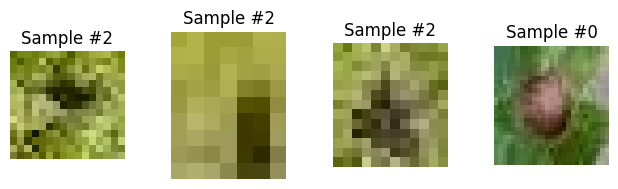

In [5]:
#grape_dataset = GrapeVineClassificationDataset(root_dir="../Datasets/DatasetClassification/", split='train', val_size=0.2, test_size=0.1)
grape_dataset = GrapeVineClassificationDataset(root_dir="./DatasetClassification/", split='train', val_size=0.2, test_size=0.1)

print(grape_dataset.get_classes())

fig = plt.figure()

i = 0
for image, label in grape_dataset:

    ax = plt.subplot(1, 4, i + 1)
    plt.tight_layout()
    ax.set_title("Sample #{}".format(label))
    ax.axis("off")
    #COnvert to see the image
    plt.imshow(image)

    if i == 3:
        plt.show()
        break

    i+=1

## Load Dataset

In [10]:
train_dataset = GrapeVineClassificationDataset(root_dir="../../Datasets/DatasetClassificationWithDataAugment/", split='train', val_size=0.2, test_size=0.1,
                                 transform=train_transform)

val_dataset = GrapeVineClassificationDataset(root_dir="../../Datasets/DatasetClassificationWithDataAugment/", split='val', val_size=0.2, test_size=0.1,
                                 transform=transform)   

test_dataset = GrapeVineClassificationDataset(root_dir="../../Datasets/DatasetClassificationWithDataAugment/", split='test', val_size=0.2, test_size=0.1,
                                 )

Number of images in train split: 83999
Number of images in val split: 24000
Number of images in test split: 12001


In [11]:
train_loader = DataLoader(dataset=train_dataset,
                          batch_size=BATCH_SIZE,
                          shuffle=True)

val_loader = DataLoader(dataset=val_dataset,
                         batch_size=BATCH_SIZE,
                         shuffle=False)

In [12]:
# Let's check out what we've created
print(f"DataLoader: {train_loader, val_loader}")
print(f"Length of train_loader: {len(train_loader)} batches of {BATCH_SIZE}...")
print(f"Length of val_loader: {len(val_loader)} batches of {BATCH_SIZE}...")

DataLoader: (<torch.utils.data.dataloader.DataLoader object at 0x7fc8d56a1310>, <torch.utils.data.dataloader.DataLoader object at 0x7fc8d56a1b50>)
Length of train_loader: 657 batches of 128...
Length of val_loader: 188 batches of 128...


## Load model

In [13]:
device = "cuda:2"  if torch.cuda.is_available() else "cpu"
print(f"Using Device: {device}")

Using Device: cuda:2


In [14]:
import torch
from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights

from PIL import Image

# Load the pre-trained model and image processor
#processor = AutoImageProcessor.from_pretrained("facebook/dinov2-base")
model = mobilenet_v3_small(weights=MobileNet_V3_Small_Weights, progress=True)
model.classifier[-1].out_features = 3
model.to(device)

# Set the model to evaluation mode
#model.eval()
model.train()

/home/vmarmelo/.local/lib/python3.8/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V3_Small_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V3_Small_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


MobileNetV3(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
      (2): Hardswish()
    )
    (1): InvertedResidual(
      (block): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), groups=16, bias=False)
          (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
          (2): ReLU(inplace=True)
        )
        (1): SqueezeExcitation(
          (avgpool): AdaptiveAvgPool2d(output_size=1)
          (fc1): Conv2d(16, 8, kernel_size=(1, 1), stride=(1, 1))
          (fc2): Conv2d(8, 16, kernel_size=(1, 1), stride=(1, 1))
          (activation): ReLU()
          (scale_activation): Hardsigmoid()
        )
        (2): Conv2dNormActivation(
          (0): Conv2d(16, 16, kernel_size=(1, 1), 

In [15]:
criterion = nn.CrossEntropyLoss() # Measure how wrong our model is
optimizer = torch.optim.Adam(params=model.parameters(), # update our model's parameters to try and reduce the loss
                             lr=LEARNING_RATE)

In [17]:
import pandas as pd

def train(model, loader, optimizer, criterion):
    # Set the mode of the model into training
    model.train()

    total_loss, correct = 0, 0 

    for x, y in loader:      
 
        # Moving (Sending) our data into the target device
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        # 1. Forward pass (model outputs raw logits)
        out = model(x)
        # 2. Calculate loss (per batch)
        loss = criterion(out, y)
        # 3. Perform backpropgation
        loss.backward()
        # 4. Perforam Gradient Descent
        optimizer.step()

        total_loss += loss.item() * x.size(0)
        correct += (out.argmax(1) == y).sum().item()

    # You have to scale the loss (Normlization step to make the loss general across all batches)
    return total_loss / len(loader.dataset), correct / len(loader.dataset)

def evaluate(model, loader):

    model.eval() # Set the mode of the model into evlauation

    correct = 0
    with torch.inference_mode():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            correct += (out.argmax(dim=1) == y).sum().item()
            
    return correct / len(loader.dataset)

In [18]:
from tqdm.auto import tqdm

### Training
train_accuracies, test_accuracies = [], []
train_losses = [] 

for epoch in tqdm(range(EPOCHS)):
    train_loss, train_acc = train(model, train_loader, optimizer, criterion)
    train_losses.append(train_loss)
    test_acc = evaluate(model, val_loader)
    train_accuracies.append(train_acc)
    test_accuracies.append(test_acc)
    print(f"Epoch: {epoch+1}/{EPOCHS}, Train loss: {train_loss:.4f}, Train acc: {train_acc:.4f}%, Test acc: {test_acc:.4f}")

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch: 1/100, Train loss: 0.4894, Train acc: 0.8218%, Test acc: 0.8947
Epoch: 2/100, Train loss: 0.3437, Train acc: 0.8625%, Test acc: 0.9017
Epoch: 3/100, Train loss: 0.3179, Train acc: 0.8723%, Test acc: 0.9169
Epoch: 4/100, Train loss: 0.3012, Train acc: 0.8792%, Test acc: 0.9200
Epoch: 5/100, Train loss: 0.2878, Train acc: 0.8870%, Test acc: 0.9241
Epoch: 6/100, Train loss: 0.2797, Train acc: 0.8901%, Test acc: 0.9265
Epoch: 7/100, Train loss: 0.2747, Train acc: 0.8914%, Test acc: 0.9255
Epoch: 8/100, Train loss: 0.2647, Train acc: 0.8955%, Test acc: 0.9266
Epoch: 9/100, Train loss: 0.2604, Train acc: 0.8957%, Test acc: 0.9312
Epoch: 10/100, Train loss: 0.2545, Train acc: 0.8994%, Test acc: 0.9249
Epoch: 11/100, Train loss: 0.2480, Train acc: 0.9000%, Test acc: 0.9347
Epoch: 12/100, Train loss: 0.2438, Train acc: 0.9030%, Test acc: 0.9359
Epoch: 13/100, Train loss: 0.2391, Train acc: 0.9058%, Test acc: 0.9333
Epoch: 14/100, Train loss: 0.2329, Train acc: 0.9071%, Test acc: 0.9339
E

In [19]:
torch.save(model.state_dict(), "./mobileNetV3WithTransformImageNet.pt")

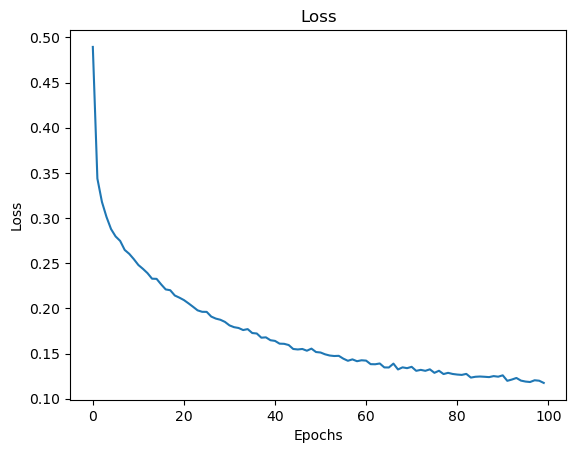

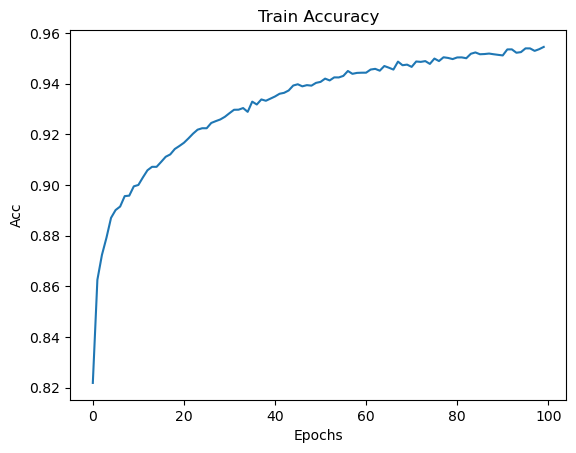

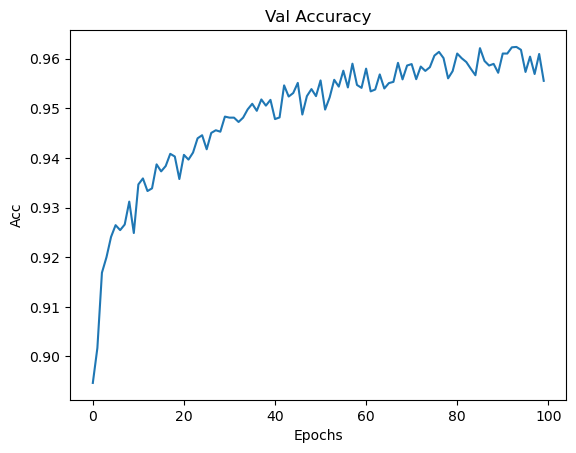

In [27]:
import matplotlib.pyplot as plt


plt.plot(train_losses)
plt.title("Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.show()


plt.plot(train_accuracies)
plt.title("Train Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Acc")
plt.show()


plt.plot(test_accuracies)
plt.title("Val Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Acc")
plt.show()



In [20]:
import os
import cv2
from PIL import Image

import numpy as np

true_values = []
pred_values = []

i = 0

model.eval()


for image, label in test_dataset:

    true_values.append(label)

    data = transform(Image.fromarray(image.astype('uint8')))
    data = data.unsqueeze(0).to(device)

    print(data.shape)

    with torch.no_grad():
        output = model(data)
        logits = output
        #print(logits)
        predicted_class = logits.argmax(-1).item()

    #print("Classe prevista: " + str(class_coding[predicted_class]))

    pred_values.append(predicted_class)

    print(f"Image {i}")

    i+=1


torch.Size([1, 3, 224, 224])
Image 0
torch.Size([1, 3, 224, 224])
Image 1
torch.Size([1, 3, 224, 224])
Image 2
torch.Size([1, 3, 224, 224])
Image 3
torch.Size([1, 3, 224, 224])
Image 4
torch.Size([1, 3, 224, 224])
Image 5
torch.Size([1, 3, 224, 224])
Image 6
torch.Size([1, 3, 224, 224])
Image 7
torch.Size([1, 3, 224, 224])
Image 8
torch.Size([1, 3, 224, 224])
Image 9
torch.Size([1, 3, 224, 224])
Image 10
torch.Size([1, 3, 224, 224])
Image 11
torch.Size([1, 3, 224, 224])
Image 12
torch.Size([1, 3, 224, 224])
Image 13
torch.Size([1, 3, 224, 224])
Image 14
torch.Size([1, 3, 224, 224])
Image 15
torch.Size([1, 3, 224, 224])
Image 16
torch.Size([1, 3, 224, 224])
Image 17
torch.Size([1, 3, 224, 224])
Image 18
torch.Size([1, 3, 224, 224])
Image 19
torch.Size([1, 3, 224, 224])
Image 20
torch.Size([1, 3, 224, 224])
Image 21
torch.Size([1, 3, 224, 224])
Image 22
torch.Size([1, 3, 224, 224])
Image 23
torch.Size([1, 3, 224, 224])
Image 24
torch.Size([1, 3, 224, 224])
Image 25
torch.Size([1, 3, 224,

In [21]:
conf_matrix = [
    [0, 0, 0],
    [0, 0, 0],
    [0, 0, 0]
]

for i in range(len(true_values)):
    conf_matrix[true_values[i]][pred_values[i]] += 1

In [22]:
conf_matrix

[[3895, 56, 49], [340, 3614, 46], [60, 37, 3904]]

In [23]:
from sklearn.metrics import f1_score, precision_score, recall_score

f1_score_model = f1_score(true_values, pred_values, average=None)
precision_model = precision_score(true_values, pred_values, average=None)
recall_model = recall_score(true_values, pred_values, average=None)

In [24]:
print(f"Precision (BlackRot, Esca, LeafBlight): {precision_model}") 
print(f"Average Precision: {sum(precision_model)/len(precision_model)}") 

Precision (BlackRot, Esca, LeafBlight): [0.90686845 0.97491233 0.97624406]
Average Precision: 0.9526749469104394


In [25]:
print(f"Recall (BlackRot, Esca, LeafBlight): {recall_model}") 
print(f"Average Recall: {sum(recall_model)/len(recall_model)}") 

Recall (BlackRot, Esca, LeafBlight): [0.97375    0.9035     0.97575606]
Average Recall: 0.9510020203282513


In [26]:
f1_score_model
print(f"F1-Scores (BlackRot, Esca, LeafBlight): {f1_score_model}") 
print(f"Average F1-Score: {sum(f1_score_model)/len(f1_score_model)}") 

F1-Scores (BlackRot, Esca, LeafBlight): [0.93911995 0.93784871 0.976     ]
Average F1-Score: 0.9509895535813516
